# Improved inverse ice-sheet solution

Open this file in PyCharm or Jupyter and select **Run All**, or run each code cell from top to bottom with **Shift+Enter**. No terminal arguments are needed.

Select a Python kernel with NumPy and Matplotlib installed. Keep `icemodel.py`, `coordinates.npy`, `surface.npy`, and `ux.npy` together in the folder set below. This notebook contains all improvement functions, so it does not need `run_inverse_ice.py`.

The noise model is unchanged. We smooth the noisy surface and fit an equivalent slope equation to avoid dividing by noisy slopes. Smoothing can introduce bias, and the fit is not guaranteed to recover the true bed.

## 1. Set the data folder

In [9]:
from pathlib import Path
import importlib.util
import numpy as np

# Edit this path on your own computer.
# If the data files are beside the notebook, you can use Path.cwd().
DATA_DIR = Path(r"C:\Users\O. Sonia Bäckström\Desktop\Inverse Modeling")
data_dir = DATA_DIR.resolve()
for name in ["icemodel.py", "coordinates.npy", "surface.npy", "ux.npy"]:
    if not (data_dir / name).is_file():
        raise FileNotFoundError(f"Missing {data_dir / name}. Update DATA_DIR above.")
print("Data folder:", data_dir)


Data folder: C:\Users\O. Sonia Bäckström\Desktop\Inverse Modeling


## 2. Define the numerical functions
Run this cell once. It defines the model, smoothing, amplitude fitting and forward simulation. No SciPy dependency is required.

In [10]:
"""Numerical improvements for the supplied icemodel exercise (NumPy only)."""
import numpy as np

class InverseIceModel:
    def __init__(self, reference, x, angle=0.2, A=300., rho=9.138e-19,
                 grav=9.7692e15, n=3):
        self.reference = reference
        self.x = np.asarray(x, dtype=float)
        if self.x.ndim != 1 or len(self.x) < 5 or not np.all(np.isfinite(self.x)):
            raise ValueError('x must be a finite 1D array with at least five points.')
        steps = np.diff(self.x)
        if np.any(steps <= 0) or not np.allclose(steps, steps[0]):
            raise ValueError('The reference derivative needs a uniform increasing grid.')
        if not np.isclose(self.x[0], 0):
            raise ValueError('This exercise assumes a domain starting at zero.')
        if n != 3:
            raise ValueError('The supplied vertical-velocity implementation assumes n=3.')
        self.dx = steps[0]
        self.L = self.x[-1]
        self.angle, self.A, self.rho, self.grav, self.n = angle,A,rho,grav,n
        self.base = reference.CreateBedRock(angle, [0.,0.], self.x, self.L)
        self.B = np.column_stack([
            reference.CreateBedRock(angle, a, self.x, self.L)-self.base
            for a in ([1.,0.], [0.,1.])])
        self.K = 2*A*(rho*grav)**3/4
        D2 = np.diff(np.eye(len(self.x)), n=2, axis=0)
        eigenvalues, self.Q = np.linalg.eigh(D2.T @ D2)
        self.eigenvalues = np.maximum(eigenvalues, 0.)
        self.lambdas = np.logspace(-3,5,65)
        self.gains = 1/(1+self.lambdas[:,None]*self.eigenvalues)

    def check(self, values):
        values = np.asarray(values,dtype=float)
        if values.shape != self.x.shape or not np.all(np.isfinite(values)):
            raise ValueError('Input arrays must be finite and match x.')
        return values

    def bed(self,a):
        return self.base + self.B @ np.asarray(a,dtype=float)

    def velocities(self,h,b):
        return self.reference.VelocityAndSurfaceGradient(
            b,h,self.dx,self.rho,self.grav,self.A,self.n)

    def smooth_surface(self,h):
        """Second-difference regularization; choose lambda using surface-only GCV."""
        h=self.check(h)
        z=self.Q.T@h
        rss=np.sum(((1-self.gains)*z)**2,axis=1)
        gcv=rss/(len(h)-self.gains.sum(axis=1))**2
        j=int(np.argmin(gcv))
        hs=self.Q@(self.gains[j]*z)
        return hs, {'lambda':float(self.lambdas[j]),
                    'effective_degrees_of_freedom':float(self.gains[j].sum()),
                    'lambda_at_search_boundary':j in (0,len(self.lambdas)-1)}

    def direct(self,h,u):
        """Original inversion, with finite-value and rank checks."""
        h,u=self.check(h),self.check(u)
        slope=self.velocities(h,self.base)[0]
        den=-self.K*slope**3
        ratio=np.full_like(h,np.nan)
        np.divide(u,den,out=ratio,where=den!=0)
        valid=np.isfinite(ratio)&(ratio>0)
        H=np.full_like(h,np.nan)
        H[valid]=ratio[valid]**.25
        if valid.sum()<2 or np.linalg.matrix_rank(self.B[valid])<2:
            raise ValueError('Not enough independent valid points to estimate two amplitudes.')
        a=np.linalg.lstsq(self.B[valid],h[valid]-H[valid]-self.base[valid],rcond=None)[0]
        return {'a':a,'H':H,'b':h-H,'slope':slope,'valid_count':int(valid.sum()),
                'positive_fitted_thickness':bool(np.all(h-self.bed(a)>0))}

    def fit_slope(self,h,u,smooth=True,max_iter=150):
        """Fit s_pred = cbrt(-u/K)/(h-b(a))^(4/3), without dividing by slope.

        This is a transformed-residual estimator, not a maximum-likelihood
        solution for the original multiplicative observation errors.
        """
        h,u=self.check(h),self.check(u)
        hs,info=self.smooth_surface(h) if smooth else (h.copy(),{'lambda':0.})
        target=self.velocities(hs,self.base)[0]
        scale=float(np.sqrt(np.mean(target**2)))
        if scale<=1e-14 or np.linalg.norm(u)==0:
            raise ValueError('Near-zero signal cannot identify the amplitudes reliably.')
        c=np.cbrt(-u/self.K)
        a=np.zeros(2)
        Hmin=1e-6  # metres, numerical positivity floor rather than a physical prior
        if np.any(hs-self.bed(a)<=Hmin):
            raise ValueError('The baseline bed is not a feasible initial guess.')
        def residual_jacobian(q):
            H=hs-self.bed(q)
            predicted=c*H**(-4/3)
            residual=(predicted-target)/scale
            jacobian=((4/3)*c*H**(-7/3))[:,None]*self.B/scale
            return residual,jacobian
        converged=False
        for iteration in range(max_iter):
            r,J=residual_jacobian(a)
            if np.linalg.matrix_rank(J)<2:
                raise ValueError('The amplitudes are not locally identifiable.')
            step=np.linalg.lstsq(J,-r,rcond=None)[0]
            if np.linalg.norm(step)<1e-8*(1+np.linalg.norm(a)):
                converged=True
                break
            cost=float(r@r)
            for power in range(35):
                trial=a+step*2.**(-power)
                if np.any(hs-self.bed(trial)<=Hmin):
                    continue
                rr,_=residual_jacobian(trial)
                if rr@rr<cost:
                    a=trial
                    break
            else:
                converged=np.linalg.norm(J.T@r,ord=np.inf)<1e-7
                break
        if not converged:
            raise RuntimeError('Slope fit did not converge; do not silently use its amplitudes.')
        r,J=residual_jacobian(a)
        bed=self.bed(a)
        _,pred_u,pred_w=self.velocities(hs,bed)
        return {'a':a,'surface':hs,'bed':bed,'H':hs-bed,'slope':target,
                'predicted_ux':pred_u,'predicted_uz':pred_w,
                'velocity_rmse':float(np.sqrt(np.mean((pred_u-u)**2))),
                'slope_rmse':float(scale*np.sqrt(np.mean(r*r))),
                'jacobian_condition':float(np.linalg.cond(J)),
                'iterations':iteration+1,**info}

    def simulate(self,a,years=200.,dt=.1,offset=800.):
        if dt<=0 or years<=0 or not np.isclose(years/dt,round(years/dt)):
            raise ValueError('Positive years must be an integer multiple of positive dt.')
        b=self.bed(a)
        h=self.reference.CreateInitialSurface(self.angle,offset,self.x,self.L)
        for _ in range(int(round(years/dt))):
            if not np.all(np.isfinite(h)) or np.any(h-b<=0):
                raise RuntimeError('Forward simulation became non-finite or lost positive thickness.')
            s,u,w=self.velocities(h,b)
            h=h+dt*(w-u*s)
        if not np.all(np.isfinite(h)) or np.any(h-b<=0):
            raise RuntimeError('Invalid final simulation state.')
        s,u,w=self.velocities(h,b)  # synchronize velocities with final surface
        return {'surface':h,'bed':b,'slope':s,'ux':u,'uz':w}


## 3. Load the reference model and observations

In [11]:
# Load this exact reference file, avoiding an unrelated installed module.
spec = importlib.util.spec_from_file_location('exercise_icemodel', data_dir / 'icemodel.py')
reference = importlib.util.module_from_spec(spec)
spec.loader.exec_module(reference)

x = np.load(data_dir / 'coordinates.npy')
h = np.load(data_dir / 'surface.npy')
ux = np.load(data_dir / 'ux.npy')
model = InverseIceModel(reference, x)


## 4. Compare both methods using the same 2% noise sample
The seed reproduces the original notebook sample. The clean fit is an evaluation reference, not independently known ground truth. Smoothing strength is selected using the noisy surface only.

In [12]:
clean = model.direct(h, ux)
rng = np.random.RandomState(42)
h_noisy = h * (1 + 0.02 * rng.randn(len(h)))
ux_noisy = ux * (1 + 0.02 * rng.randn(len(ux)))
original = model.direct(h_noisy, ux_noisy)
improved = model.fit_slope(h_noisy, ux_noisy)

print('\nAMPLITUDE COMPARISON: original 2% noise sample, seed 42')
print(f'{"Method":22s} {"a1":>12s} {"a2":>12s}')
for label, a in [('Clean-data reference', clean['a']),
                 ('Original noisy method', original['a']),
                 ('Improved noisy method', improved['a'])]:
    print(f'{label:22s} {a[0]:12.6f} {a[1]:12.6f}')
print('\nOriginal valid thickness points:', original['valid_count'], '/', len(x))
print('Selected smoothing strength:', improved['lambda'])
if improved['lambda_at_search_boundary']:
    print('Check smoothing: selected lambda is at the search boundary.')
print('Minimum improved thickness (m):', improved['H'].min())
print('Improved changes from clean reference (%):',
      100 * np.abs(improved['a'] - clean['a']) / np.abs(clean['a']))
print('These changes use the clean-data estimates as a reference, not independently known truth.')



AMPLITUDE COMPARISON: original 2% noise sample, seed 42
Method                           a1           a2
Clean-data reference       0.800001    -0.400001
Original noisy method      0.611839    -0.520106
Improved noisy method      0.814338    -0.381278

Original valid thickness points: 40 / 51
Selected smoothing strength: 42.169650342858226
Minimum improved thickness (m): 457.97372066704355
Improved changes from clean reference (%): [1.79210301 4.68074354]
These changes use the clean-data estimates as a reference, not independently known truth.


## 5. Run the 200-year simulation and compare time steps
This preserves the exercise’s clean reconstructed bed. The 800 m initial offset is measured above the baseline, not above the bumpy bed everywhere.

In [13]:
# Preserve the original exercise's clean reconstructed bed for the forward run.
forward = model.simulate(clean['a'], years=200, dt=0.1)
refined = model.simulate(clean['a'], years=200, dt=0.05)
difference = np.max(np.abs(forward['surface'] - refined['surface']))
print('\n200-year forward simulation, using clean reconstructed bed:')
print(f'Maximum surface difference, dt=0.1 versus 0.05: {difference:.8f} m')
print('Velocities are in m/year. Final velocities match the final surface.')



200-year forward simulation, using clean reconstructed bed:
Maximum surface difference, dt=0.1 versus 0.05: 0.00066443 m
Velocities are in m/year. Final velocities match the final surface.


## 6. Plot the results

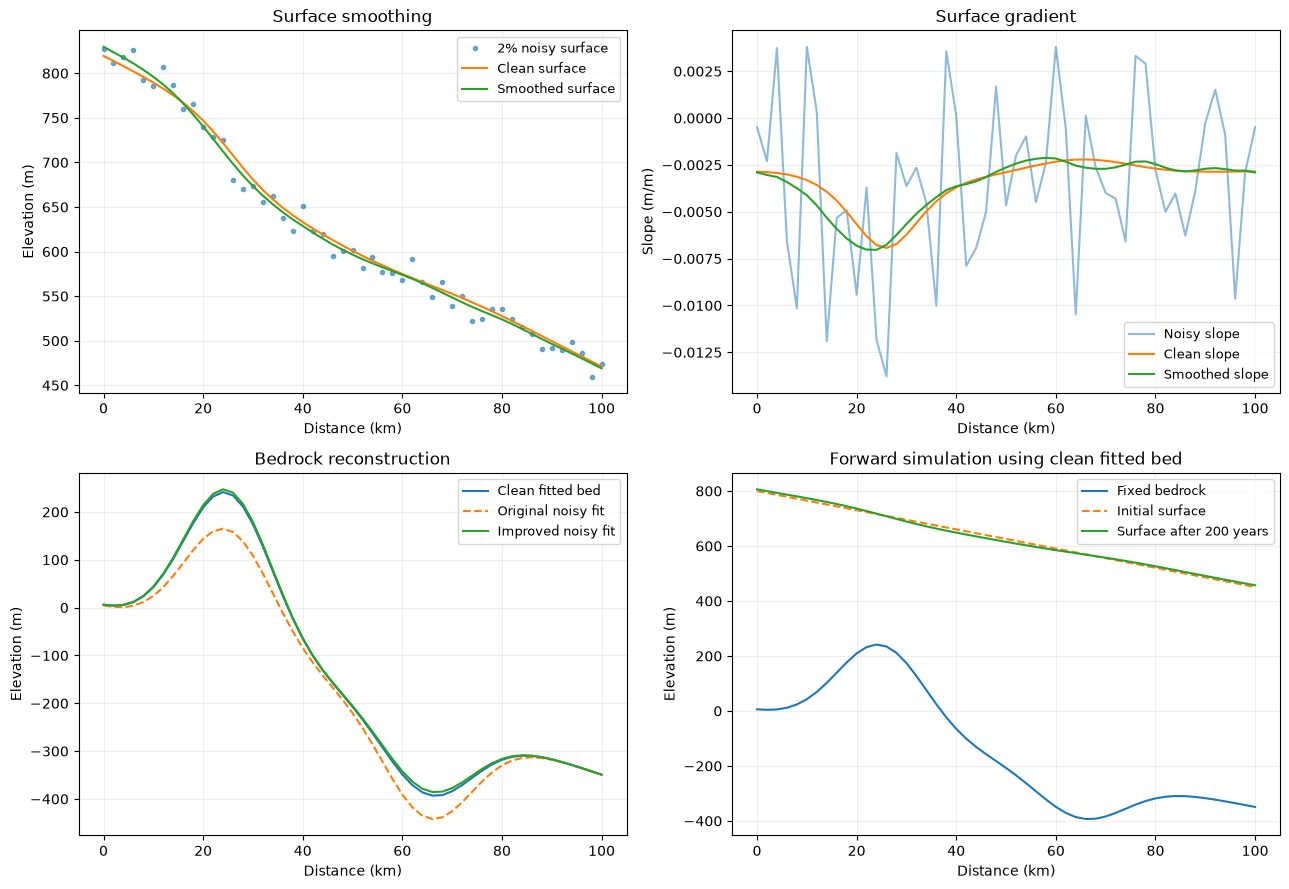

In [14]:
import matplotlib.pyplot as plt
km = x / 1000
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]
ax.plot(km, h_noisy, '.', alpha=0.6, label='2% noisy surface')
ax.plot(km, h, label='Clean surface')
ax.plot(km, improved['surface'], label='Smoothed surface')
ax.set(title='Surface smoothing', ylabel='Elevation (m)')

ax = axes[0, 1]
ax.plot(km, original['slope'], alpha=0.5, label='Noisy slope')
ax.plot(km, clean['slope'], label='Clean slope')
ax.plot(km, improved['slope'], label='Smoothed slope')
ax.set(title='Surface gradient', ylabel='Slope (m/m)')

ax = axes[1, 0]
ax.plot(km, model.bed(clean['a']), label='Clean fitted bed')
ax.plot(km, model.bed(original['a']), '--', label='Original noisy fit')
ax.plot(km, improved['bed'], label='Improved noisy fit')
ax.set(title='Bedrock reconstruction', ylabel='Elevation (m)')

ax = axes[1, 1]
ax.plot(km, forward['bed'], label='Fixed bedrock')
ax.plot(km, reference.CreateInitialSurface(0.2, 800, x, model.L), '--', label='Initial surface')
ax.plot(km, forward['surface'], label='Surface after 200 years')
ax.set(title='Forward simulation using clean fitted bed', ylabel='Elevation (m)')
for ax in axes.flat:
    ax.set_xlabel('Distance (km)')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


## Expected comparison

| Method | a1 | a2 |
|---|---:|---:|
| Clean-data reference | 0.800001 | -0.400001 |
| Original noisy method | 0.611839 | -0.520106 |
| Improved noisy method | 0.814338 | -0.381278 |

These values apply to the supplied files and seed 42. They illustrate one sample, not guaranteed accuracy for every noise realization. Velocities use metres per year.